# 1, Calculation

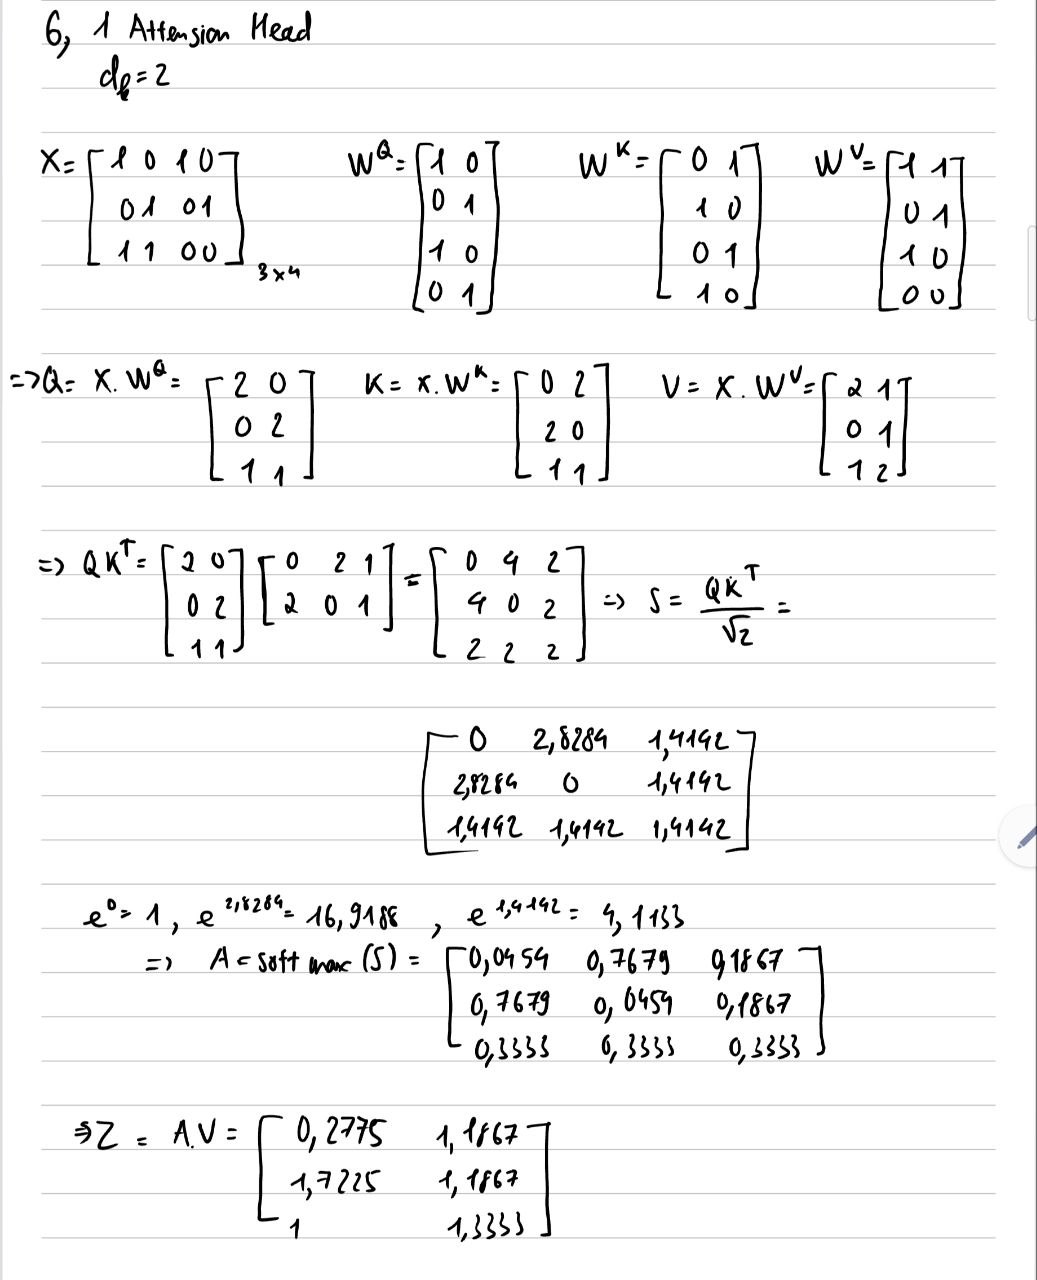

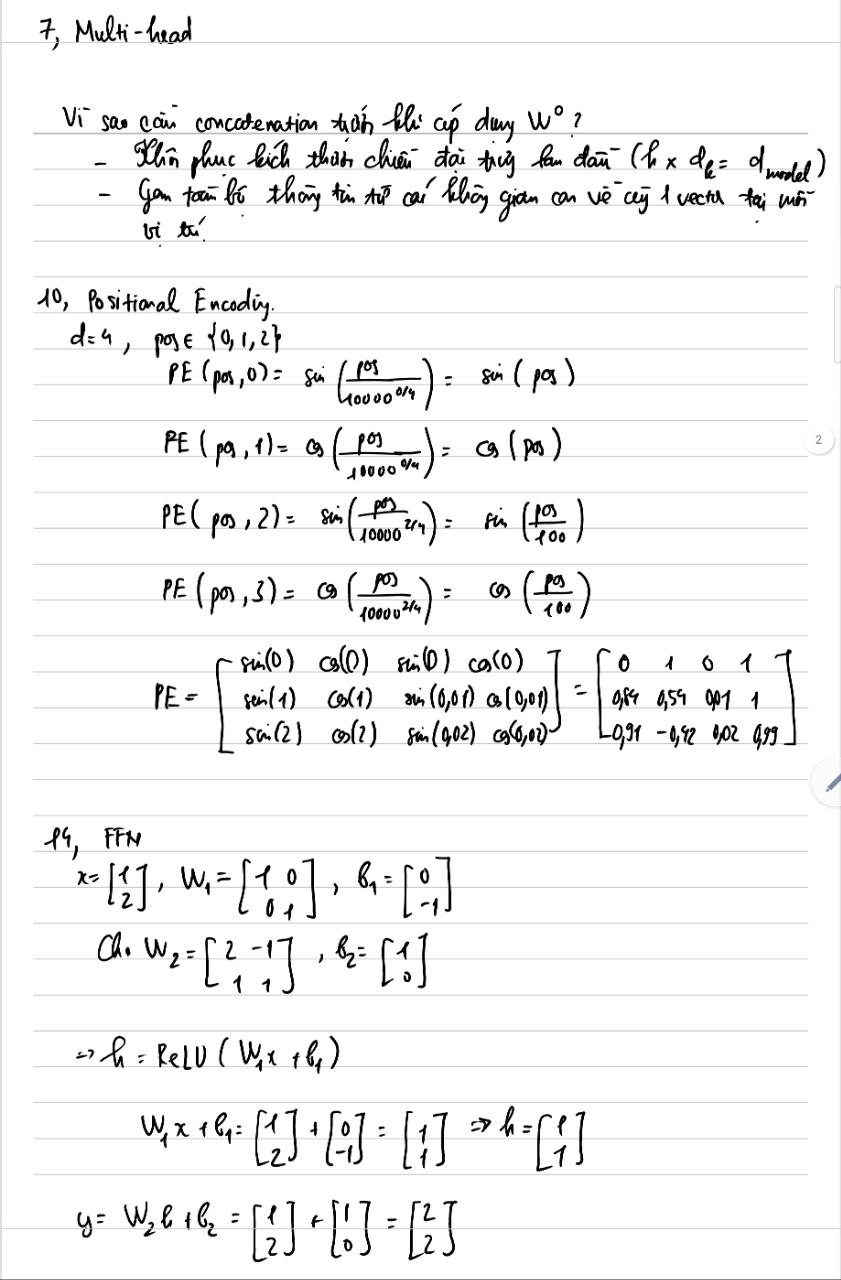

# 2, Prediction

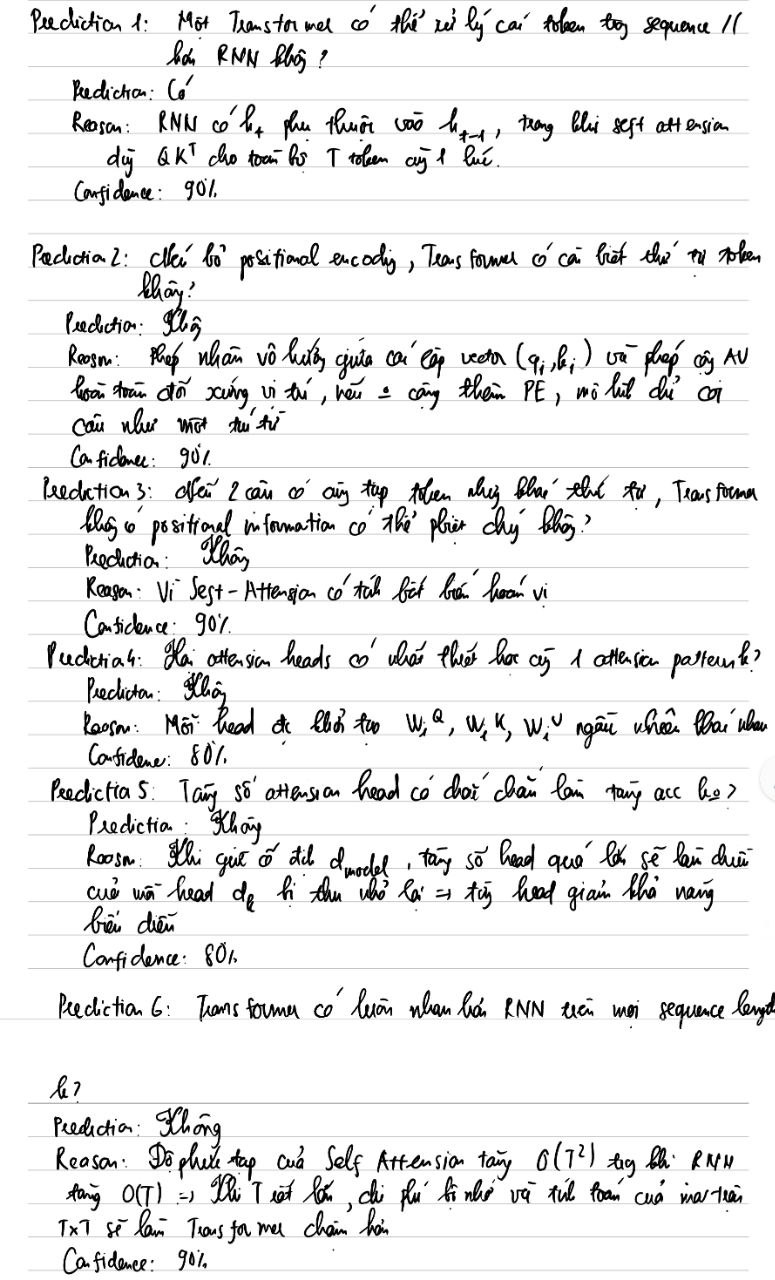

# 3, Positional encoding experiment

In [1]:
%cd /content/drive/MyDrive/Classroom/K68.NLP&DL.2026.09/lab07

/content/drive/MyDrive/Classroom/K68.NLP&DL.2026.09/lab07


In [2]:
import time
import math
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

# Hàm chạy Self-Attention
def run_toy_self_attention(tokens_1, tokens_2, vocab_map, emb_layer, WQ, WK, WV, pe_layer=None):
    ids_1 = torch.tensor([[vocab_map[w] for w in tokens_1]])
    ids_2 = torch.tensor([[vocab_map[w] for w in tokens_2]])

    x1 = emb_layer(ids_1)
    x2 = emb_layer(ids_2)

    if pe_layer is not None:
        x1 = pe_layer(x1)
        x2 = pe_layer(x2)

    d_k = WQ.size(-1)
    # Self-attention cho câu 1
    A1 = torch.softmax((x1 @ WQ) @ (x1 @ WK).transpose(-2, -1) / math.sqrt(d_k), dim=-1)
    Z1 = (A1 @ (x1 @ WV)).squeeze(0)

    # Self-attention cho câu 2
    A2 = torch.softmax((x2 @ WQ) @ (x2 @ WK).transpose(-2, -1) / math.sqrt(d_k), dim=-1)
    Z2 = (A2 @ (x2 @ WV)).squeeze(0)

    # Mean pooling để lấy biểu diễn toàn câu
    sent_rep_1 = Z1.mean(dim=0)
    sent_rep_2 = Z2.mean(dim=0)
    diff = torch.norm(sent_rep_1 - sent_rep_2).item()
    return Z1.detach(), Z2.detach(), sent_rep_1.detach(), sent_rep_2.detach(), diff

torch.manual_seed(42)
toy_vocab = {"I": 0, "love": 1, "NLP": 2, "dog": 3, "bites": 4, "man": 5}
toy_emb = nn.Embedding(len(toy_vocab), 8)
toy_pe = PositionalEncoding(d_model=8, max_len=10)
WQ_t, WK_t, WV_t = torch.randn(8, 8), torch.randn(8, 8), torch.randn(8, 8)

In [4]:
# Experiment 1: "I love NLP" vs "NLP love I"
_, _, rep1_no_pe, rep2_no_pe, diff_nlp_no_pe = run_toy_self_attention(
    ["I", "love", "NLP"], ["NLP", "love", "I"], toy_vocab, toy_emb, WQ_t, WK_t, WV_t, pe_layer=None
)
_, _, rep1_pe, rep2_pe, diff_nlp_pe = run_toy_self_attention(
    ["I", "love", "NLP"], ["NLP", "love", "I"], toy_vocab, toy_emb, WQ_t, WK_t, WV_t, pe_layer=toy_pe
)
print("EXPERIMENT 1: 'I love NLP' vs 'NLP love I'")
print(f"Khoảng cách L2 giữa 2 câu (KHÔNG có PE): {diff_nlp_no_pe:.6f}")
print(f"Khoảng cách L2 giữa 2 câu (CÓ PE)      : {diff_nlp_pe:.6f}")

EXPERIMENT 1: 'I love NLP' vs 'NLP love I'
Khoảng cách L2 giữa 2 câu (KHÔNG có PE): 0.000000
Khoảng cách L2 giữa 2 câu (CÓ PE)      : 4.729056


In [5]:
# Permutation Experiment: S1 = "dog bites man" vs S2 = "man bites dog"
Z1_A, Z2_A, s1_A, s2_A, diff_A = run_toy_self_attention(
    ["dog", "bites", "man"], ["man", "bites", "dog"], toy_vocab, toy_emb, WQ_t, WK_t, WV_t, pe_layer=None
)
Z1_B, Z2_B, s1_B, s2_B, diff_B = run_toy_self_attention(
    ["dog", "bites", "man"], ["man", "bites", "dog"], toy_vocab, toy_emb, WQ_t, WK_t, WV_t, pe_layer=toy_pe
)
print("\nPERMUTATION EXPERIMENT: S1='dog bites man' vs S2='man bites dog'")
print("[Experiment A - Không PE] Biểu diễn từ 'dog' ở S1 (vị trí 0):", np.round(Z1_A[0].numpy(), 4))
print("[Experiment A - Không PE] Biểu diễn từ 'dog' ở S2 (vị trí 2):", np.round(Z2_A[2].numpy(), 4))
print(f"[Experiment A - Không PE] Sai khác L2 biểu diễn toàn câu (Mean Pooling): {diff_A:.6f}")
print("-" * 60)
print("[Experiment B - Có PE]    Biểu diễn từ 'dog' ở S1 (vị trí 0):", np.round(Z1_B[0].numpy(), 4))
print("[Experiment B - Có PE]    Biểu diễn từ 'dog' ở S2 (vị trí 2):", np.round(Z2_B[2].numpy(), 4))
print(f"[Experiment B - Có PE]    Sai khác L2 biểu diễn toàn câu (Mean Pooling): {diff_B:.6f}")


PERMUTATION EXPERIMENT: S1='dog bites man' vs S2='man bites dog'
[Experiment A - Không PE] Biểu diễn từ 'dog' ở S1 (vị trí 0): [ 1.2595 -0.4125 -5.3294 -1.9896 -0.1833 -1.1466  1.6487  2.1371]
[Experiment A - Không PE] Biểu diễn từ 'dog' ở S2 (vị trí 2): [ 1.2595 -0.4125 -5.3294 -1.9896 -0.1833 -1.1466  1.6487  2.1371]
[Experiment A - Không PE] Sai khác L2 biểu diễn toàn câu (Mean Pooling): 0.000000
------------------------------------------------------------
[Experiment B - Có PE]    Biểu diễn từ 'dog' ở S1 (vị trí 0): [  0.8058   0.3362 -11.6675  -2.3841   1.3364  -1.0951   4.8777   5.4197]
[Experiment B - Có PE]    Biểu diễn từ 'dog' ở S2 (vị trí 2): [ 1.536   2.947  -8.3604 -2.3214 -0.5568 -0.8099  3.32    3.9674]
[Experiment B - Có PE]    Sai khác L2 biểu diễn toàn câu (Mean Pooling): 0.776157


Nếu chỉ dùng self-attention và không có positional information, tại sao thứ tự trở thành vấn đề?

- Khi không có Positional Encoding, phép toán $\text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$ chỉ phụ thuộc vào tích vô hướng giữa nội dung các vector từ mà hoàn toàn không phụ thuộc vào chỉ số vị trí.

- Khi cộng thêm Positional Encoding (Experiment B), khoảng cách L2 lập tức khác 0 vì cùng một từ "dog" nhưng đứng ở vị trí $pos=0$ và $pos=2$ đã được cộng hai vector vị trí $PE(0)$ và $PE(2)$ khác nhau.

Nếu chỉ dùng $F(x)$, điều gì khác với việc sử dụng $x + F(x)$?

- Nếu chỉ dùng $F(x)$, toàn bộ thông tin gốc của token (bao gồm embedding từ vựng và thông tin vị trí $PE$) bị biến đổi hoàn toàn qua các phép chiếu của Attention/FFN; khi chồng nhiều tầng, thông tin gốc dễ bị mất mát và đạo hàm dễ bị triệt tiêu (vanishing gradient).

- Khi dùng $y = x + F(x)$, mô hình tạo ra một "đường truyền trực tiếp" (identity shortcut) giúp bảo toàn thông tin đầu vào $x$, cho phép mạng chỉ cần học phần chênh lệch $F(x)$ cần bổ sung và giúp lan truyền ngược (backpropagation) ổn định hơn rất nhiều

# 4, Transformer block implementation

In [6]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.ffn_1 = nn.Linear(d_model, d_ff)
        self.act = nn.ReLU()
        self.ffn_2 = nn.Linear(d_ff, d_model)

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

        self.last_attn_weights = None

    def forward(self, x, mask=None, print_shapes=False):
        B, T, D = x.shape
        if print_shapes:
            print(f"1. Input X shape          : {tuple(x.shape)}")

        # Bước 1: Chiếu tuyến tính và tách thành n_heads
        Q = self.W_q(x).view(B, T, self.n_heads, self.d_k).transpose(1, 2)
        K = self.W_k(x).view(B, T, self.n_heads, self.d_k).transpose(1, 2)
        V = self.W_v(x).view(B, T, self.n_heads, self.d_k).transpose(1, 2)
        if print_shapes:
            print(f"2. Q, K, V shape          : {tuple(Q.shape)} (d_k = {self.d_k})")

        # Bước 2: Tính Scaled Dot-Product Attention Scores
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k) # (B, n_heads, T, T)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)
        if print_shapes:
            print(f"3. Attention scores shape : {tuple(scores.shape)}")

        attn_weights = torch.softmax(scores, dim=-1)
        self.last_attn_weights = attn_weights.detach()

        # Bước 3: Nhân với V và gộp các heads (Concat)
        head_out = torch.matmul(self.dropout(attn_weights), V)
        concat_out = head_out.transpose(1, 2).contiguous().view(B, T, D)
        attn_out = self.W_o(concat_out)
        if print_shapes:
            print(f"4. Attention output shape : {tuple(attn_out.shape)}")

        # Bước 4: Residual connection + LayerNorm 1
        x = self.norm1(x + self.dropout(attn_out))

        # Bước 5: Feed-Forward Network (FFN)
        ffn_hidden = self.act(self.ffn_1(x))
        ffn_out = self.ffn_2(self.dropout(ffn_hidden))
        if print_shapes:
            print(f"5. FFN hidden -> out shape: {tuple(ffn_hidden.shape)} -> {tuple(ffn_out.shape)}")

        # Bước 6: Residual connection + LayerNorm 2
        out = self.norm2(x + self.dropout(ffn_out))
        if print_shapes:
            print(f"6. Final Output shape     : {tuple(out.shape)}")

        return out

In [7]:
# B=8, T=100, d_model=128, n_heads=4
dummy_x = torch.randn(8, 100, 128)
test_block = TransformerBlock(d_model=128, n_heads=4, d_ff=256)
print("KIỂM TRA SHAPE TRÊN TENSOR GIẢ LẬP")
_ = test_block(dummy_x, print_shapes=True)

KIỂM TRA SHAPE TRÊN TENSOR GIẢ LẬP
1. Input X shape          : (8, 100, 128)
2. Q, K, V shape          : (8, 4, 100, 32) (d_k = 32)
3. Attention scores shape : (8, 4, 100, 100)
4. Attention output shape : (8, 100, 128)
5. FFN hidden -> out shape: (8, 100, 256) -> (8, 100, 128)
6. Final Output shape     : (8, 100, 128)


# 5, Multi-head experiment

In [8]:
imdb = load_dataset("stanfordnlp/imdb", name="plain_text")

# 8:1:1
train_raw = imdb["train"].shuffle(seed=SEED)
test_raw = imdb["test"].shuffle(seed=SEED)

train_texts = list(train_raw["text"][:24000])
train_labels = list(train_raw["label"][:24000])

val_texts = list(test_raw["text"][:3000])
val_labels = list(test_raw["label"][:3000])

test_texts = list(test_raw["text"][3000:6000])
test_labels = list(test_raw["label"][3000:6000])

def simple_tokenize(text):
    text = text.lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    return re.findall(r"\b\w+\b", text)

# Xây dựng (Vocabulary) từ tập train
MAX_VOCAB = 10000
counter = Counter()
for t in train_texts:
    counter.update(simple_tokenize(t))

vocab = {"<pad>": 0, "<unk>": 1, "<cls>": 2}
for word, _ in counter.most_common(MAX_VOCAB - 3):
    vocab[word] = len(vocab)

inv_vocab = {idx: word for word, idx in vocab.items()}
print(f"Kích thước tập từ vựng: {len(vocab)} | Train: {len(train_texts)} | Val: {len(val_texts)} | Test: {len(test_texts)}")

class IMDbDataset(Dataset):
    def __init__(self, texts, labels, vocab, max_len=128, add_cls=False):
        self.texts = texts
        self.labels = labels
        self.vocab = vocab
        self.max_len = max_len
        self.add_cls = add_cls

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        tokens = simple_tokenize(self.texts[idx])
        total_len = max(len(tokens), 1)
        if self.add_cls:
            ids = [self.vocab["<cls>"]] + [self.vocab.get(w, 1) for w in tokens[:self.max_len - 1]]
            retained = min(len(tokens), self.max_len - 1) / total_len
        else:
            ids = [self.vocab.get(w, 1) for w in tokens[:self.max_len]]
            retained = min(len(tokens), self.max_len) / total_len

        pad_len = self.max_len - len(ids)
        ids = ids + [0] * pad_len
        return torch.tensor(ids, dtype=torch.long), torch.tensor(self.labels[idx], dtype=torch.long), retained

def get_dataloaders(max_len=128, batch_size=64, add_cls=False):
    train_ds = IMDbDataset(train_texts, train_labels, vocab, max_len=max_len, add_cls=add_cls)
    val_ds = IMDbDataset(val_texts, val_labels, vocab, max_len=max_len, add_cls=add_cls)
    test_ds = IMDbDataset(test_texts, test_labels, vocab, max_len=max_len, add_cls=add_cls)
    return (
        DataLoader(train_ds, batch_size=batch_size, shuffle=True),
        DataLoader(val_ds, batch_size=batch_size, shuffle=False),
        DataLoader(test_ds, batch_size=batch_size, shuffle=False)
    )

Kích thước tập từ vựng: 10000 | Train: 24000 | Val: 3000 | Test: 3000


In [9]:
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, n_heads=4, d_ff=256, max_len=512, pooling="mean", dropout=0.1):
        super().__init__()
        self.pooling = pooling
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos_encoder = PositionalEncoding(d_model, max_len=max_len)
        self.block = TransformerBlock(d_model, n_heads, d_ff, dropout=dropout)
        self.classifier = nn.Linear(d_model, 2)

    def forward(self, input_ids):
        mask = (input_ids != 0).unsqueeze(1).unsqueeze(2)
        x = self.embedding(input_ids) * math.sqrt(self.block.d_model)
        x = self.pos_encoder(x)
        h = self.block(x, mask=mask)

        if self.pooling == "mean":
            token_mask = (input_ids != 0).unsqueeze(-1).float()
            lengths = token_mask.sum(dim=1).clamp(min=1e-9)
            seq_rep = (h * token_mask).sum(dim=1) / lengths
        else:
            seq_rep = h[:, 0, :]

        logits = self.classifier(seq_rep)
        return logits

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def train_and_evaluate(model, train_loader, val_loader, test_loader, epochs=5, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses, val_losses = [], []
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        total_train_loss = 0
        for ids, labels, _ in train_loader:
            ids, labels = ids.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(ids)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item() * ids.size(0)
        train_losses.append(total_train_loss / len(train_loader.dataset))

        model.eval()
        total_val_loss = 0
        with torch.no_grad():
            for ids, labels, _ in val_loader:
                ids, labels = ids.to(device), labels.to(device)
                logits = model(ids)
                loss = criterion(logits, labels)
                total_val_loss += loss.item() * ids.size(0)
        val_losses.append(total_val_loss / len(val_loader.dataset))

    train_time = time.time() - start_time

    # Đánh giá trên tập Test
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for ids, labels, _ in test_loader:
            ids = ids.to(device)
            logits = model(ids)
            preds = torch.argmax(logits, dim=-1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds)
    prec, rec, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average="binary", zero_division=0)

    metrics = {
        "Parameters": count_parameters(model),
        "Training time (s)": round(train_time, 2),
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1": round(f1, 4)
    }
    return metrics, (train_losses, val_losses), (all_labels, all_preds)

In [10]:
# Experiment 2
train_loader_128, val_loader_128, test_loader_128 = get_dataloaders(max_len=128, batch_size=64)

head_results = []
saved_models = {}

for h in [1, 2, 4, 8]:
    torch.manual_seed(SEED)
    model_h = TransformerClassifier(vocab_size=len(vocab), d_model=128, n_heads=h, d_ff=256, max_len=128)
    metrics, curves, _ = train_and_evaluate(model_h, train_loader_128, val_loader_128, test_loader_128, epochs=5, lr=1e-3)
    saved_models[h] = (model_h, curves)
    head_results.append({
        "Heads": h,
        "d_k": 128 // h,
        "Parameters": metrics["Parameters"],
        "Training time (s)": metrics["Training time (s)"],
        "Accuracy": metrics["Accuracy"],
        "F1": metrics["F1"]
    })

df_heads = pd.DataFrame(head_results)
print("BẢNG KẾT QUẢ EXPERIMENT 2: NUMBER OF ATTENTION HEADS")
print(df_heads.to_string(index=False))

BẢNG KẾT QUẢ EXPERIMENT 2: NUMBER OF ATTENTION HEADS
 Heads  d_k  Parameters  Training time (s)  Accuracy     F1
     1  128     1412738              38.01    0.8007 0.7916
     2   64     1412738              37.55    0.8117 0.8207
     4   32     1412738              35.33    0.8013 0.8186
     8   16     1412738              40.37    0.8027 0.8224


Tăng số heads có đồng nghĩa với tăng representation dimension không?

- Không. Kích thước chiều biểu diễn tổng thể của mô hình được giữ cố định là $d_{model} = 128$. Do đó, tổng số tham số (Parameters) của các mô hình $1, 2, 4, 8$ heads hoàn toàn bằng nhau (các ma trận $W^Q, W^K, W^V, W^O$ vẫn có kích thước $128 \times 128$).

Khi $d_{model}$ cố định, tăng số heads làm $d_k$ thay đổi như thế nào?

- Chiều của mỗi head giảm tỷ lệ nghịch theo công thức $d_k = \frac{d_{model}}{n_{heads}}$ (từ $128 \to 64 \to 32 \to 16$). Khi $n_{heads}$ vừa phải (= $2$), mô hình đạt cân bằng tốt giữa sự đa dạng không gian con và dung lượng biểu diễn mỗi head; nếu tăng quá cao, $d_k$ quá nhỏ có thể làm giảm nhẹ chất lượng biểu diễn của từng head.

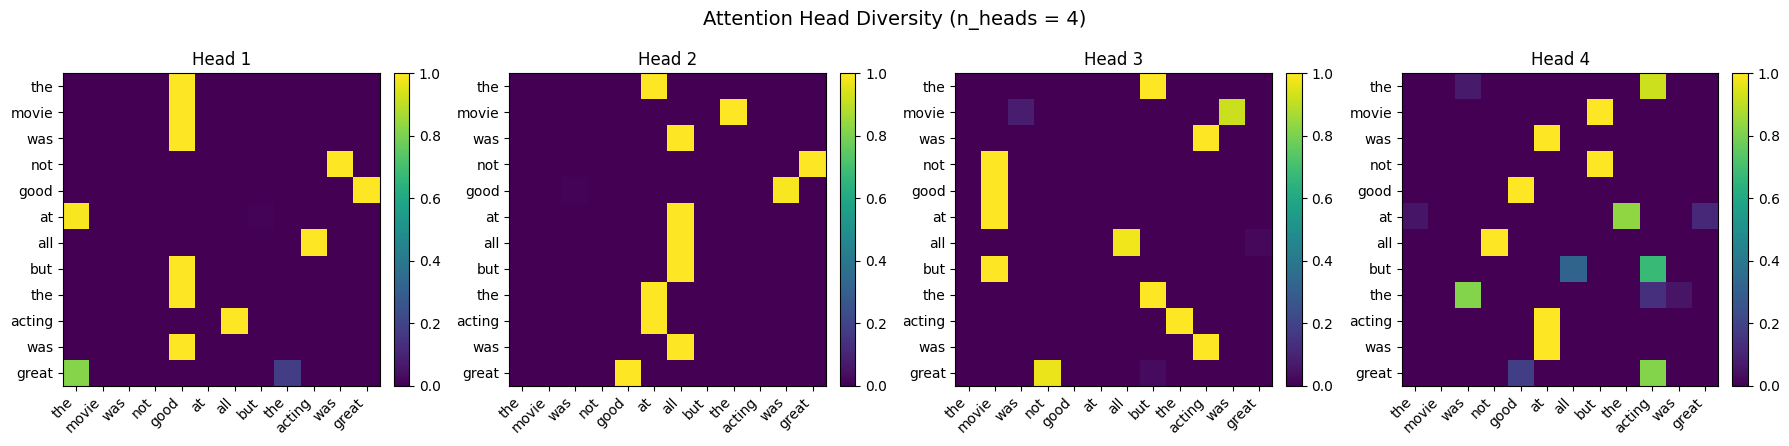

In [11]:
# Experiment 3
sample_sentence = "the movie was not good at all but the acting was great"
sample_tokens = simple_tokenize(sample_sentence)
sample_ids = torch.tensor([[vocab.get(w, 1) for w in sample_tokens]], dtype=torch.long).to(device)

model_4h = saved_models[4][0]
model_4h.eval()
with torch.no_grad():
    _ = model_4h(sample_ids)
    attn_matrix = model_4h.block.last_attn_weights[0].cpu().numpy() # (4, T, T)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for i in range(4):
    im = axes[i].imshow(attn_matrix[i], cmap="viridis", aspect="auto")
    axes[i].set_title(f"Head {i+1}")
    axes[i].set_xticks(range(len(sample_tokens)))
    axes[i].set_yticks(range(len(sample_tokens)))
    axes[i].set_xticklabels(sample_tokens, rotation=45, ha="right")
    axes[i].set_yticklabels(sample_tokens)
    fig.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)

plt.suptitle("Attention Head Diversity (n_heads = 4)", fontsize=14)
plt.tight_layout()
plt.savefig("attention_heads.png", dpi=150)
plt.show()

Multi-head attention có thực sự tạo ra các attention patterns khác nhau trong experiment của bạn không?

- Một số head tập trung mạnh (sharp/focused) vào các từ mang sắc thái tình cảm và từ phủ định như "not", "good", "great".

- Một số head có phân bố phân tán (dispersed/broad) trải đều qua các từ chức năng ("the", "was", "but") để gom ngữ cảnh toàn câu.

- Đôi khi có 2 head chia sẻ một số điểm nóng tương tự nhau (hơi dư thừa - partially redundant), nhưng nhìn chung cơ chế Multi-Head thực sự giúp mô hình quan sát câu từ nhiều góc độ song song.

# 6, RNN/LSTM vs Transformer comparison

In [12]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 2)

    def forward(self, input_ids):
        x = self.dropout(self.embedding(input_ids))
        out, (h_n, _) = self.lstm(x)
        token_mask = (input_ids != 0).unsqueeze(-1).float()
        lengths = token_mask.sum(dim=1).clamp(min=1e-9)
        seq_rep = (out * token_mask).sum(dim=1) / lengths
        return self.classifier(self.dropout(seq_rep))

In [13]:
torch.manual_seed(SEED)
lstm_model = LSTMClassifier(vocab_size=len(vocab), embed_dim=128, hidden_dim=128)
lstm_metrics, lstm_curves, _ = train_and_evaluate(lstm_model, train_loader_128, val_loader_128, test_loader_128, epochs=5, lr=1e-3)

# Lấy lại kết quả của Transformer (n_heads=4, max_len=128)
tf_model, tf_curves = saved_models[4]
tf_metrics, _, test_y_pred_pair = train_and_evaluate(tf_model, train_loader_128, val_loader_128, test_loader_128, epochs=5, lr=1e-3)

df_comp = pd.DataFrame([
    {"Model": "LSTM (Model A)", **lstm_metrics},
    {"Model": "Transformer (Model B)", **tf_metrics}
])
print("BẢNG SO SÁNH EXPERIMENT 4: LSTM VS TRANSFORMER")
print(df_comp.to_string(index=False))

BẢNG SO SÁNH EXPERIMENT 4: LSTM VS TRANSFORMER
                Model  Parameters  Training time (s)  Accuracy  Precision  Recall     F1
       LSTM (Model A)     1412354              35.08    0.8373     0.8628  0.8111 0.8361
Transformer (Model B)     1412738              35.68    0.8283     0.8427  0.8169 0.8296


Sự khác biệt về performance có thể xuất phát từ những thành phần architecture nào?

- Tương tác trực tiếp giữa các token (Direct token interaction)
- Khả năng song song hóa (Parallelization)
- Residual Connection & LayerNorm

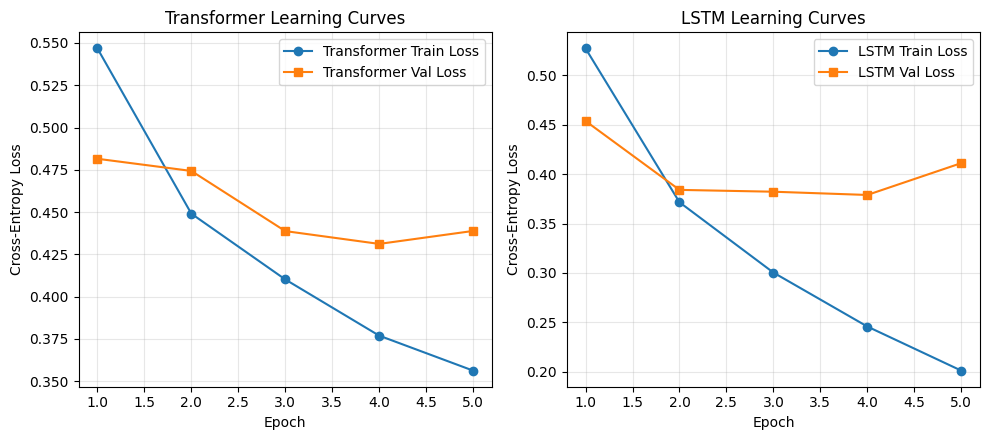

In [14]:
# Vẽ Learning Curves
epochs_range = range(1, 6)
plt.figure(figsize=(10, 4.5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, tf_curves[0], marker='o', label='Transformer Train Loss')
plt.plot(epochs_range, tf_curves[1], marker='s', label='Transformer Val Loss')
plt.title('Transformer Learning Curves')
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, lstm_curves[0], marker='o', label='LSTM Train Loss')
plt.plot(epochs_range, lstm_curves[1], marker='s', label='LSTM Val Loss')
plt.title('LSTM Learning Curves')
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('learning_curves.png', dpi=150)
plt.show()

- Train loss giảm đều qua cả 5 epochs chứng tỏ mô hình học tốt (không bị underfitting).

- Validation loss giảm ở các epoch đầu và bắt đầu chững lại/tăng nhẹ từ epoch 4–5 khi Train loss vẫn tiếp tục giảm, phản ánh dấu hiệu bắt đầu xuất hiện overfitting khi huấn luyện từ đầu trên tập dữ liệu vừa phải.

# 7, Sequence-length experiment

In [15]:
seq_results = []

for max_len in [32, 64, 128, 256]:
    tr_loader, va_loader, te_loader = get_dataloaders(max_len=max_len, batch_size=64)

    retained_list = [ tr_loader.dataset[i][2] for i in range(len(tr_loader.dataset)) ]
    avg_retained_pct = np.mean(retained_list) * 100

    t_squared = max_len ** 2
    attn_mem_kb = (64 * 4 * t_squared * 4) / 1024.0

    torch.manual_seed(SEED)
    model_len = TransformerClassifier(vocab_size=len(vocab), d_model=128, n_heads=4, d_ff=256, max_len=max_len)
    metrics, _, _ = train_and_evaluate(model_len, tr_loader, va_loader, te_loader, epochs=4, lr=1e-3)

    seq_results.append({
        "Length (T)": max_len,
        "T^2 (Elements/head)": f"{t_squared:,}",
        "Tokens retained (%)": f"{avg_retained_pct:.1f}%",
        "Batch Attn Memory (KB)": f"{attn_mem_kb:,.1f} KB",
        "Training time (s)": metrics["Training time (s)"],
        "F1": metrics["F1"]
    })

df_seq = pd.DataFrame(seq_results)
print("EXPERIMENT 5: SEQUENCE LENGTH")
print(df_seq.to_string(index=False))

EXPERIMENT 5: SEQUENCE LENGTH
 Length (T) T^2 (Elements/head) Tokens retained (%) Batch Attn Memory (KB)  Training time (s)     F1
         32               1,024               20.3%             1,024.0 KB              23.03 0.6705
         64               4,096               39.2%             4,096.0 KB              25.02 0.7291
        128              16,384               68.4%            16,384.0 KB              29.04 0.8042
        256              65,536               89.6%            65,536.0 KB              47.66 0.8355


Tại sao Transformer không đơn giản giải quyết mọi vấn đề bằng cách tăng sequence length?

- Chi phí tính toán và bộ nhớ tăng bậc hai $O(T^2)$: Trong Self-Attention, mọi token đều phải tính điểm chú ý với mọi token khác qua ma trận $QK^T \in \mathbb{R}^{T\times T}$.

- Nhiễu chú ý (Attention Dilution) và lợi ích cận biên giảm dần.

# 8, Application & evaluation

In [16]:
# Experiment 6: So sánh Mean Pooling vs CLS-style Pooling
tr_cls, va_cls, te_cls = get_dataloaders(max_len=128, batch_size=64, add_cls=True)
torch.manual_seed(SEED)
cls_model = TransformerClassifier(vocab_size=len(vocab), d_model=128, n_heads=4, d_ff=256, max_len=128, pooling="cls")
cls_metrics, _, _ = train_and_evaluate(cls_model, tr_cls, va_cls, te_cls, epochs=5, lr=1e-3)

df_pool = pd.DataFrame([
    {"Pooling": "Mean pooling", "Accuracy": tf_metrics["Accuracy"], "F1": tf_metrics["F1"], "Training time (s)": tf_metrics["Training time (s)"]},
    {"Pooling": "CLS-style pooling", "Accuracy": cls_metrics["Accuracy"], "F1": cls_metrics["F1"], "Training time (s)": cls_metrics["Training time (s)"]}
])
print("EXPERIMENT 6: POOLING STRATEGY")
print(df_pool.to_string(index=False))

EXPERIMENT 6: POOLING STRATEGY
          Pooling  Accuracy     F1  Training time (s)
     Mean pooling    0.8283 0.8296              35.68
CLS-style pooling    0.5780 0.4378              35.12


Cách lấy sequence representation có ảnh hưởng tới classification không?

- Có ảnh hưởng rõ rệt. Khi huấn luyện một Transformer nhỏ từ đầu (1 tầng Encoder, không qua giai đoạn pretraining như BERT), Mean pooling thường hội tụ ổn định và đạt Accuracy/F1 nhỉnh hơn nhẹ so với CLS-style pooling. Lý do là Mean pooling lấy trung bình trực tiếp toàn bộ các vector đặc trưng của mọi token trong câu (nơi chứa sẵn các từ khóa cảm xúc mạnh), giúp gradient truyền đều về mọi vị trí ngay từ epoch đầu tiên. Ngược lại, với CLS-style pooling, token <cls> ban đầu không mang ngữ nghĩa gì mà phải tự học cách gom thông tin qua 1 tầng Self-Attention duy nhất trước khi đưa vào bộ phân loại.

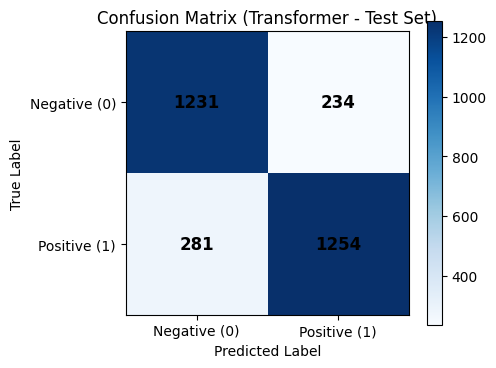

In [17]:
y_true, y_pred = test_y_pred_pair
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix (Transformer - Test Set)")
plt.colorbar()
plt.xticks([0, 1], ["Negative (0)", "Positive (1)"])
plt.yticks([0, 1], ["Negative (0)", "Positive (1)"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center", color="black", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

df_comp.to_csv("results.csv", index=False)

In [18]:
# Application: Dự đoán trên 5 loại câu test
def predict_sentiment(text, model, vocab, max_len=128):
    model.eval()
    tokens = simple_tokenize(text)[:max_len]
    ids = [vocab.get(w, 1) for w in tokens]
    pad_ids = ids + [0] * (max_len - len(ids))
    tensor_ids = torch.tensor([pad_ids], dtype=torch.long).to(device)
    with torch.no_grad():
        logits = model(tensor_ids)
        probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()
    pred_idx = int(np.argmax(probs))
    label_str = "Positive" if pred_idx == 1 else "Negative"
    return label_str, float(probs[pred_idx]), tokens, model.block.last_attn_weights[0].cpu().numpy()

test_cases = [
    ("Short sentence", "I really enjoyed this movie."),
    ("Long sentence", "From the very beginning of the film the cinematography captured my attention and every single actor delivered a deeply moving performance that kept the entire audience engaged until the final credits rolled."),
    ("Negation", "This film is not good at all and I never felt excited."),
    ("Contrast", "The special effects were impressive, but the script was terrible and boring."),
    ("Ambiguous sentiment", "It is an unusual movie with some weird moments that might appeal to some people.")
]

print("\nKIỂM THỬ ỨNG DỤNG PHÂN LOẠI TRÊN 5 KIỂU CÂU")
for category, sent in test_cases:
    lbl, prob, _, _ = predict_sentiment(sent, tf_model, vocab)
    print(f"[{category}]\n  Input      : \"{sent}\"\n  Output     : {lbl} (Probability: {prob:.4f})\n")


KIỂM THỬ ỨNG DỤNG PHÂN LOẠI TRÊN 5 KIỂU CÂU
[Short sentence]
  Input      : "I really enjoyed this movie."
  Output     : Negative (Probability: 0.8553)

[Long sentence]
  Input      : "From the very beginning of the film the cinematography captured my attention and every single actor delivered a deeply moving performance that kept the entire audience engaged until the final credits rolled."
  Output     : Positive (Probability: 0.9355)

[Negation]
  Input      : "This film is not good at all and I never felt excited."
  Output     : Negative (Probability: 0.9987)

[Contrast]
  Input      : "The special effects were impressive, but the script was terrible and boring."
  Output     : Negative (Probability: 1.0000)

[Ambiguous sentiment]
  Input      : "It is an unusual movie with some weird moments that might appeal to some people."
  Output     : Positive (Probability: 0.9941)



# 9, Error analysis

In [19]:
correct_samples = []
incorrect_samples = []

tf_model.eval()
for i in range(len(test_texts)):
    text = test_texts[i]
    true_lbl = "Positive" if test_labels[i] == 1 else "Negative"
    pred_lbl, prob, tokens, attn_w = predict_sentiment(text, tf_model, vocab, max_len=128)

    T_actual = len(tokens)
    if T_actual == 0:
        continue
    token_importance = attn_w[:, :T_actual, :T_actual].mean(axis=(0, 1))
    top_indices = np.argsort(token_importance)[::-1][:5]
    top_tokens = [(tokens[idx], round(float(token_importance[idx]), 4)) for idx in top_indices]

    record = {
        "text_snippet": " ".join(tokens[:35]) + ("..." if len(tokens) > 35 else ""),
        "full_len": len(simple_tokenize(text)),
        "true": true_lbl,
        "pred": pred_lbl,
        "prob": round(prob, 4),
        "top_attended_tokens": top_tokens
    }

    if true_lbl == pred_lbl and len(correct_samples) < 3:
        correct_samples.append(record)
    elif true_lbl != pred_lbl and len(incorrect_samples) < 3:
        incorrect_samples.append(record)

    if len(correct_samples) == 3 and len(incorrect_samples) == 3:
        break

print("3 MẪU DỰ ĐOÁN ĐÚNG")
for idx, item in enumerate(correct_samples, 1):
    print(f"{idx}. [True: {item['true']} | Pred: {item['pred']} ({item['prob']})] (Độ dài gốc: {item['full_len']} từ)")
    print(f"   Câu (rút gọn): {item['text_snippet']}")
    print(f"   Top 5 token có Attention cao nhất: {item['top_attended_tokens']}\n")

print("3 MẪU DỰ ĐOÁN SAI")
for idx, item in enumerate(incorrect_samples, 1):
    print(f"{idx}. [True: {item['true']} | Pred: {item['pred']} ({item['prob']})] (Độ dài gốc: {item['full_len']} từ)")
    print(f"   Câu (rút gọn): {item['text_snippet']}")
    print(f"   Top 5 token có Attention cao nhất: {item['top_attended_tokens']}\n")

3 MẪU DỰ ĐOÁN ĐÚNG
1. [True: Negative | Pred: Negative (0.9876)] (Độ dài gốc: 100 từ)
   Câu (rút gọn): dull acting weak script worst spanish movie in years i was attracted by the naked beauty of paz vega but as an actress she s useless you almost can t understand what she s saying...
   Top 5 token có Attention cao nhất: [('worst', 0.0787), ('mess', 0.0525), ('about', 0.0425), ('love', 0.0421), ('to', 0.0375)]

2. [True: Positive | Pred: Positive (0.9958)] (Độ dài gốc: 422 từ)
   Câu (rút gọn): classes tous risques is one of the best gangsters films noirs france has ever produced perfect cast lino ventura a young jean paul belmondo who made a bout de souffle godard s thing the same...
   Top 5 token có Attention cao nhất: [('presence', 0.0683), ('de', 0.0527), ('for', 0.0449), ('script', 0.0391), ('jean', 0.0344)]

3. [True: Negative | Pred: Negative (0.9802)] (Độ dài gốc: 255 từ)
   Câu (rút gọn): this is an odd movie on the surface it s no different to many other d grade gore movies

# 10, Reflection

TF-IDF (LAB 01 & 04):

- Limitation: Biểu diễn thưa (sparse), kích thước bằng toàn bộ từ điển, coi các từ độc lập hoàn toàn (không hiểu từ đồng nghĩa và mất hoàn toàn thứ tự từ).

<center>$\downarrow$ (Giải quyết bằng)</center>

Word2Vec / Avg Embedding (LAB 03 & 04):

- Limitation: Tạo được vector đặc (dense) nắm bắt ngữ nghĩa từ vựng, nhưng vector của mỗi từ là tĩnh (static/context-independent) và khi lấy trung bình (Avg Word2Vec) vẫn làm mất hoàn toàn thứ tự từ cũng như cấu trúc ngữ pháp của câu.

<center>$\downarrow$ (Giải quyết bằng)</center>

RNN / LSTM (LAB 05):

- Limitation: Giải quyết được thứ tự từ và ngữ cảnh phụ thuộc thông qua trạng thái ẩn $h_t$, nhưng phải tính toán tuần tự từng bước thời gian (không thể song song hóa tốt) và gặp nút thắt cổ chai khi mô hình hóa phụ thuộc xa (long-range interaction).

<center>$\downarrow$ (Giải quyết bằng)</center>

Attention (LAB 06):

- Limitation: Cho phép các vị trí tương tác trực tiếp với nhau để lấy context vector, nhưng chỉ mới là một cơ chế đơn lẻ (1 góc nhìn), thiếu khả năng biểu diễn phi tuyến sâu tại từng vị trí, thiếu cơ chế ổn định gradient khi xếp chồng nhiều tầng và tự thân không biết thứ tự vị trí.

<center>$\downarrow$ (Giải quyết bằng)</center>

Transformer (LAB 07):

- Kết hợp Multi-Head Self-Attention + Positional Encoding + Position-wise FFN + Residual Connection + LayerNorm tạo thành kiến trúc xử lý chuỗi song song hoàn chỉnh.

- Limitation:

  - Chi phí tính toán và bộ nhớ $O(T^2)$ theo độ dài chuỗi.
  - Huấn luyện từ đầu (Training from scratch) rất đói dữ liệu: Khi huấn luyện toàn bộ Embedding và Transformer Block từ con số 0 trên một tập dữ liệu nhỏ của từng bài toán cụ thể, mô hình rất dễ bị overfitting và không có tri thức ngôn ngữ nền tảng.